In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

In [2]:
names = open('names.txt', 'r').read().splitlines()

In [3]:
len(names)

32033

In [4]:
chars = sorted(list(set(''.join(names))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)

In [5]:
# build dataset
block_size = 3
def build_dataset(names):
    X, Y = [], []
    for w in names:
        context = [0]*block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]
    
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X,Y

import random
random.seed(42)
random.shuffle(names)
n1 = int(0.8*len(names))
n2 = int(0.9*len(names))
Xtr, Ytr = build_dataset(names[:n1])
Xdev, Ydev = build_dataset(names[n1:n2])
Xte, Yte = build_dataset(names[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [6]:
#MLP parameters
n_emb = 10
n_hidden = 200
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size,n_emb), generator=g)
w1 = torch.randn((n_emb*block_size, n_hidden), generator=g) * (5/3)/((n_emb * n_hidden)**0.5)
b1 = torch.randn(n_hidden, generator=g) * 0.01
w2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.1
b2 = torch.randn(vocab_size, generator=g) * 0
bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))
parameters = [C, w1, w2, b2, bngain, bnbias]

bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))
print(f"total parameters = {sum(p.nelement() for p in parameters)}")
for p in parameters:
    p.requires_grad = True

total parameters = 12097


In [7]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
    #minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]

    #forward pass
    emb = C[Xb]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ w1 #+ b1
    bnmean = hpreact.mean(0, keepdim=True)
    bnstd = hpreact.std(0, keepdim=True)
    hpreact = bngain * (hpreact - bnmean)/bnstd + bnbias

    with torch.no_grad():
        bnmean_running = bnmean_running*0.999 + 0.001*bnmean
        bnstd_running = bnstd_running*0.999 + 0.001*bnstd
    
    h = torch.tanh(hpreact)
    logits = h @ w2 + b2
    loss = F.cross_entropy(logits, Yb)

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    #update
    lr = 0.1 if i < max_steps/2 else 0.01
    for p in parameters:
        p.data += -lr*p.grad

    #track stats
    if i % 10000 == 0:
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.item())

      0/ 200000: 3.7900
  10000/ 200000: 2.2155
  20000/ 200000: 2.3263
  30000/ 200000: 2.4818
  40000/ 200000: 1.9920
  50000/ 200000: 2.5356
  60000/ 200000: 2.3935
  70000/ 200000: 2.0644
  80000/ 200000: 2.2963
  90000/ 200000: 2.1807
 100000/ 200000: 1.9679
 110000/ 200000: 2.2654
 120000/ 200000: 1.9413
 130000/ 200000: 2.4518
 140000/ 200000: 2.2451
 150000/ 200000: 2.2557
 160000/ 200000: 1.9403
 170000/ 200000: 1.8275
 180000/ 200000: 2.0529
 190000/ 200000: 1.9898


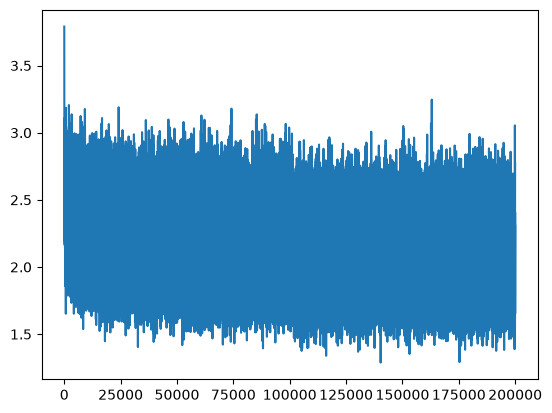

In [14]:
plt.plot(lossi)

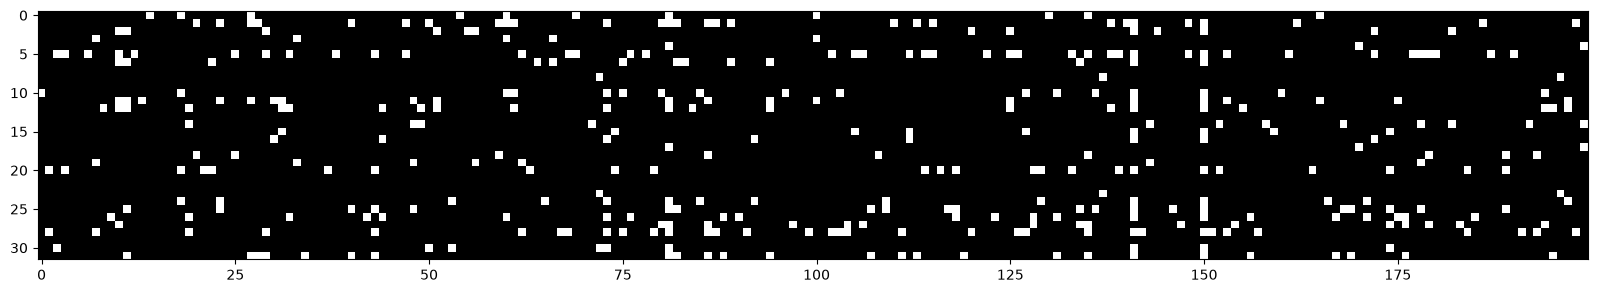

In [15]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99, cmap='gray', interpolation='nearest')

In [16]:
@torch.no_grad()
def split_loss(split):
    x,y = {
        'train': (Xtr, Ytr), 
        'val': (Xdev, Ydev), 
        'test': (Xte, Yte)
    }[split]
    emb = C[x]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ w1 + b1
    hpreact = bngain*((hpreact - bnmean_running)/bnstd_running) + bnbias
    h = torch.tanh(hpreact)
    logits = h @ w2 + b2
    loss = F.cross_entropy(logits, y)
    print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.0609962940216064
val 2.105807304382324


In [14]:
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(5):
    context = [0]*block_size
    out = []
    while True:
        emb = C[torch.tensor(context)]
        h = torch.tanh(emb.view(1, -1) @ w1 + b1)
        logits = h @ w2 + b2
        probs = F.softmax(logits, dim=1)
        
        ix = torch.multinomial(probs, num_samples=1, generator=g).item()
        out.append(itos[ix])
        context = context[1:] + [ix]
        if ix == 0:
            break
    print(f'{''.join(out)}')

carman.
amille.
khyrmyn.
reet.
khalayane.


In [ ]:
# initial loss
train 2.1267659664154053
val 2.1697638034820557

# loss after changing w2, b2 to have smaller logits
train 2.0681495666503906
val 2.132511854171753

# loss after fixing the w1, b1 weights to avoid dead neurons due to tanh
train 2.050701379776001
val 2.1072194576263428

# loss after initialising it according to the paper 
train 2.088892936706543
val 2.1274220943450928

# loss after using batch normalization
train 2.0610854625701904
val 2.1054434776306152

# loss with running mean and variance
train 2.0609962940216064
val 2.105807304382324